# Statistical Analysis and Visualization of Maize Production in Zambia Using Python
**ICD 341 Advanced Statistical Computing: Capstone Project**
Author: *Student Name*

## 1. Introduction
Maize is Zambia's staple crop, so understanding what drives district-level production and yield matters for food security planning.
This notebook analyses 10 districts over 14 years (2010–2023).

> **Data note:** the dataset is **simulated** with a fixed random seed so the project runs anywhere. Findings illustrate the methods and are **not** official statistics. Replace `data/maize_production.csv` with real survey data (same columns) to analyse real figures.

## 2. Objectives
1. Collect or obtain maize production data.
2. Clean and organise the dataset.
3. Calculate descriptive statistics.
4. Analyse production patterns.
5. Develop appropriate statistical models.
6. Visualise the results.
7. Develop an interactive dashboard (`dashboard/app.py`).
8. Present findings and recommendations.

## 3. Set-up and reproducibility
All functions live in `src/analysis.py`; every random process uses seed 123.

In [1]:
import sys
sys.path.append("../src")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import analysis as an
np.random.seed(an.SEED)
print("Seed:", an.SEED)

Seed: 123


## 4. Data collection and loading (Objective 1)

In [2]:
raw = an.load_data()
print(raw.shape)
raw.head()
print(raw.head())
print(); print(raw.dtypes)

(140, 8)
  District Province  Year  ...  Fertilizer_kg_ha  Yield_t_ha  Production_t
0   Lusaka   Lusaka  2010  ...             140.8       1.842         58826
1   Lusaka   Lusaka  2011  ...             169.4       2.569         76114
2   Lusaka   Lusaka  2012  ...             151.9       1.663         52124
3   Lusaka   Lusaka  2013  ...             148.2       2.375         79310
4   Lusaka   Lusaka  2014  ...             153.5       2.549         81306

[5 rows x 8 columns]

District                str
Province                str
Year                  int64
Area_ha               int64
Rainfall_mm         float64
Fertilizer_kg_ha    float64
Yield_t_ha          float64
Production_t          int64
dtype: object


## 5. Data cleaning (Objective 2)
The raw file has missing rainfall values. We check, then impute each with its **district median** (rainfall differs strongly between districts, so a national median would be misleading).

In [3]:
print("Missing values per column (raw):"); print(raw.isna().sum())
df = an.clean_data(raw)
print("\nMissing values after cleaning:", int(df.isna().sum().sum()))
print("Rows:", len(df))

Missing values per column (raw):
District            0
Province            0
Year                0
Area_ha             0
Rainfall_mm         5
Fertilizer_kg_ha    0
Yield_t_ha          0
Production_t        0
dtype: int64

Missing values after cleaning: 0
Rows: 140


## 6. Descriptive statistics (Objective 3)

In [4]:
print(df.describe().round(2))
print(); print(an.headline_numbers(df))
print(); print(an.district_summary(df))

          Year    Area_ha  ...  Yield_t_ha  Production_t
count   140.00     140.00  ...      140.00        140.00
mean   2016.50   59485.41  ...        2.43     147691.02
std       4.05   17903.03  ...        0.47      63164.69
min    2010.00   29626.00  ...        1.15      52124.00
25%    2013.00   48097.50  ...        2.11     104854.25
50%    2016.50   56427.50  ...        2.42     132028.50
75%    2020.00   67536.25  ...        2.71     174851.00
max    2023.00  109453.00  ...        3.72     338281.00

[8 rows x 6 columns]

{'total_production_t': 20676743, 'mean_yield_t_ha': 2.433, 'highest_district': 'Chipata', 'lowest_district': 'Lusaka'}

          Mean_Production  SD_Production  Mean_Yield  Mean_Rainfall  CV_%
District                                                                 
Chipata         256398.43       50935.99        2.69         959.60  19.9
Mkushi          229645.71       57592.65        2.81         941.33  25.1
Kabwe           163228.21       35677.70        

**Interpretation.** Chipata and Mkushi have the highest average production, largely because they have the largest planted areas. Lusaka is lowest in production (smallest area), yet its *yield* is mid-range, so production and yield tell different stories.
The coefficient of variation (CV) shows Mumbwa has the least stable production (about 29%), while Choma and Mazabuka are the most stable (about 17%).

## 7. Production patterns (Objective 4)

 Year  Production_t  Mean_Yield
 2010       1033272        1.94
 2011       1173779        2.13
 2012       1294792        2.30
 2013       1292229        2.27
 2014       1400725        2.48
 2015       1353706        2.30
 2016       1453270        2.43
 2017       1483727        2.38
 2018       1583098        2.54
 2019       1696867        2.68
 2020       1566015        2.49
 2021       1702750        2.64
 2022       1714055        2.69
 2023       1928458        2.78

Trend in mean yield: slope = 0.0512 t/ha per year, R2 = 0.846, p = 0.000


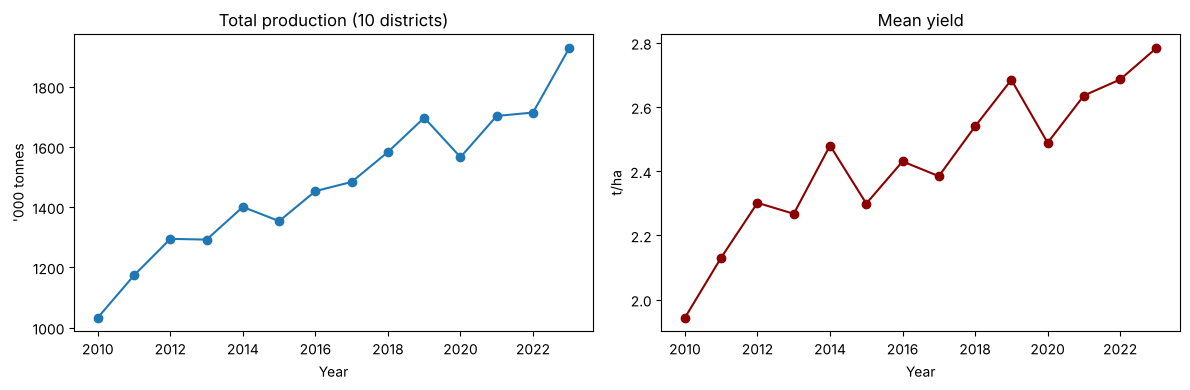

In [5]:
trend, tr = an.national_trend(df)
print(trend.round(2).to_string(index=False))
print("\nTrend in mean yield: slope = %.4f t/ha per year, R2 = %.3f, p = %.3f" % (tr["slope"], tr["r2"], tr["p_value"]))
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(trend["Year"], trend["Production_t"]/1000, marker="o"); ax[0].set(title="Total production (10 districts)", xlabel="Year", ylabel="'000 tonnes")
ax[1].plot(trend["Year"], trend["Mean_Yield"], marker="o", color="darkred"); ax[1].set(title="Mean yield", xlabel="Year", ylabel="t/ha")
plt.tight_layout(); plt.show()

**Interpretation.** Total production rises from about 1.0 million tonnes (2010) to about 1.9 million tonnes (2023), and mean yield rises by roughly **0.05 t/ha per year** (R² ≈ 0.85, p < 0.001). Part of this rise is area expansion (planted area grows about 2% a year in the data) and part is higher yield. Year-to-year dips (e.g. 2015, 2020) are consistent with rainfall variation. Whether the yield rise is a genuine time trend or is explained by other variables is tested in the regression below.

## 8. Statistical modelling (Objective 5)
### 8.1 Multiple regression of yield
$$\text{Yield}_{it} = \beta_0 + \beta_1\,\text{Rainfall}_{it} + \beta_2\,\text{Fertilizer}_{it} + \beta_3\,t + \varepsilon_{it}$$
Solved by least squares with NumPy (`np.linalg.lstsq`), with standard errors from $\hat\sigma^2 (X^\top X)^{-1}$.

In [6]:
ols = an.fit_ols(df)
print("n =", ols["n"], "| R2 = %.3f | residual SD = %.3f" % (ols["r2"], ols["sigma"]))
print(ols["table"])

n = 140 | R2 = 0.489 | residual SD = 0.340
                  Coefficient  Std_Error        t  p_value
Intercept             0.08774    0.24009  0.36546  0.71534
Rainfall_mm           0.00109    0.00016  6.95253  0.00000
Fertilizer_kg_ha      0.00678    0.00123  5.51997  0.00000
Year_trend            0.01438    0.00942  1.52653  0.12920


**Interpretation.**
* Each extra **100 mm of rainfall** is associated with about **0.11 t/ha** more yield (p < 0.001).
* Each extra **10 kg/ha of fertiliser** is associated with about **0.07 t/ha** more yield (p < 0.001).
* The year trend (about 0.014 t/ha per year) is **not statistically significant** (p ≈ 0.13). Fertiliser use rises steadily over time in the data, so once it is controlled for, the raw yield trend from Section 7 is largely accounted for by higher fertiliser use (an association, not proof of causation).
* R² ≈ 0.49: rainfall and fertiliser explain roughly half the variation in yield. The rest reflects soil, management and other factors not in the model (district effects, for example).

### 8.2 Bootstrap uncertainty for the rainfall effect

Point estimate: 0.00109
95% bootstrap CI: [0.00082, 0.00139]


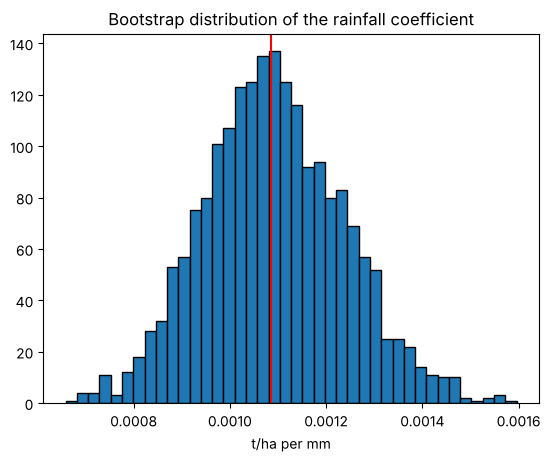

In [7]:
ci, slopes = an.bootstrap_rain_slope(df, 2000)
print("Point estimate: %.5f" % ols["beta"][1])
print("95%% bootstrap CI: [%.5f, %.5f]" % tuple(ci))
plt.hist(slopes, bins=40, edgecolor="black"); plt.axvline(ols["beta"][1], color="red")
plt.title("Bootstrap distribution of the rainfall coefficient"); plt.xlabel("t/ha per mm"); plt.show()

The interval excludes zero, which agrees with the regression p-value: the rainfall effect is robust to resampling.

### 8.3 Monte Carlo low-yield risk simulation
We simulate 20,000 seasons: rainfall is drawn from a normal distribution; yield comes from the fitted model plus residual noise. A *drought scenario* cuts mean rainfall by 15%. We estimate the probability that yield falls below 2 t/ha.

normal   mean yield = 2.53 t/ha | P(yield < 2 t/ha) = 9.2%
drought  mean yield = 2.37 t/ha | P(yield < 2 t/ha) = 17.1%


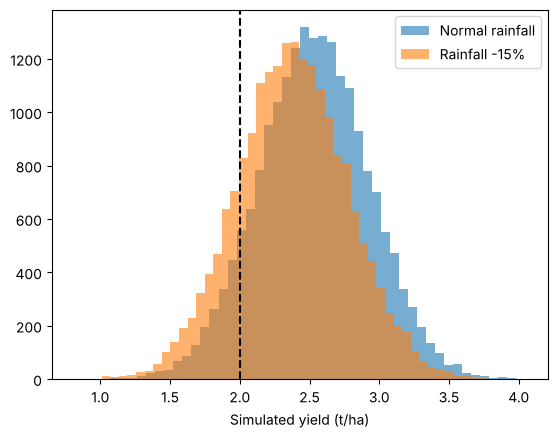

In [8]:
risk = an.drought_risk(df, ols, n_sim=20000, rain_cut=0.85, yield_threshold=2.0)
for k in ("normal", "drought"):
    print("%-8s mean yield = %.2f t/ha | P(yield < 2 t/ha) = %.1f%%" % (k, risk[k]["mean_yield"], 100*risk[k]["p_low_yield"]))
plt.hist(risk["normal"]["samples"], bins=50, alpha=.6, label="Normal rainfall")
plt.hist(risk["drought"]["samples"], bins=50, alpha=.6, label="Rainfall -15%")
plt.axvline(2.0, color="black", ls="--"); plt.legend(); plt.xlabel("Simulated yield (t/ha)"); plt.show()

**Interpretation.** A 15% rainfall shortfall roughly doubles the chance of a low-yield season (from about 9% to about 17%). Note the simulation assumes the fitted linear relationship holds and ignores extreme events, so it is a rough guide, not a forecast.

## 9. Visualisation (Objective 6)
The summary figure is also saved to `outputs/graphs.png`.

Saved: graphs.png


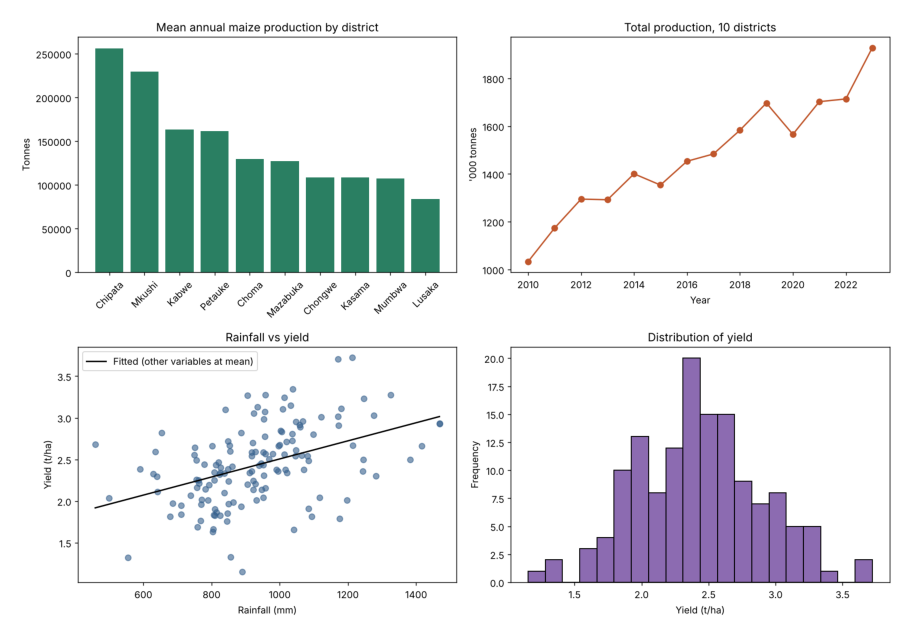

In [9]:
path = an.make_graphs(df, ols)
from matplotlib.image import imread
plt.figure(figsize=(12, 8)); plt.imshow(imread(path)); plt.axis("off"); plt.show()
print("Saved:", path.name)

## 10. Interactive dashboard (Objective 7)
The dashboard lives in `dashboard/app.py`. From the project root run:
```
streamlit run dashboard/app.py
```
It offers district/year filters, headline metrics, charts, a district explorer, the regression table and an interactive risk simulation.

## 11. Findings and recommendations (Objective 8)
**Findings**
1. Production is driven mostly by planted area; yield is driven by **rainfall** and **fertiliser**.
2. Rainfall and fertiliser effects are statistically significant and the rainfall effect is stable under bootstrapping.
3. A 15% rainfall shortfall roughly doubles the chance of a low-yield season in the simulation.
4. Districts differ in stability (CV between about 17% and 29%).

**Recommendations**
* Promote fertiliser access and drought-tolerant varieties/irrigation, especially in the more variable districts.
* Use rainfall forecasts for early warning of low-yield seasons.

**Limitations and future work**
* Data are simulated; repeat the analysis with real survey data.
* Add district effects (fixed-effects or mixed models), soil data and prices; consider Bayesian modelling (PyMC) for full uncertainty.

## 12. Conclusion
Python tools (pandas, NumPy, SciPy, Matplotlib, Streamlit) provide a reproducible workflow from raw data to interactive reporting.

## References
* Harris et al. (2020). Array programming with NumPy. *Nature* 585.
* McKinney (2010). Data structures for statistical computing in Python. *SciPy Proceedings*.
* Course notes: ICD 341 Advanced Statistical Computing, Mulungushi University.